# Facebook Comment Scraper & Analisis Sentimen (Positif, Negatif, Netral)

Notebook ini menyajikan pipeline lengkap ekstraksi data komentar Facebook tanpa API Key berbayar, pembersihan teks berbasis Regex, **Analisis Sentimen 3 Kelas (Positif, Negatif, Netral)** menggunakan leksikon bahasa Indonesia (*InSet Lexicon*) yang diperkaya dengan penanganan negasi dan kata penguat (*booster*), kategorisasi aspek isu publik (*Aspect-Based Rule Hint*), **Visualisasi Grafik & WordCloud Sentimen**, serta ekspor dataset ke file CSV berformat UTF-8 with BOM (`utf-8-sig`).

### Studi Kasus:
- **Sumber Berita**: Suaradotcom
- **Topik Postingan**: Foto viral Gubernur Kalimantan Timur (Rudy Mas’ud) bersama istri saat berada di Singapura.
- **Tautan Target**: `https://www.facebook.com/100064500378237/posts/1628147096011954/?app=fbl`
- **Tujuan**: Menganalisis opini publik mengenai etika, gaya hidup pejabat, dan persepsi masyarakat terhadap pemerintah daerah.

In [1]:
# 1. Instalasi Pustaka Dependensi (Jalankan sekali jika di Google Colab / environment baru)
# !pip install selenium beautifulsoup4 pandas matplotlib seaborn wordcloud

In [2]:
# 2. Import Library yang Diperlukan
import os
import re
import sys
import time
from typing import List, Dict, Any, Optional, Tuple
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud
from bs4 import BeautifulSoup
from selenium import webdriver
from selenium.webdriver.chrome.options import Options
from selenium.webdriver.common.by import By

print("[OK] Semua pustaka berhasil diimpor: Selenium, BeautifulSoup, Pandas, Matplotlib, Seaborn, WordCloud.")

[OK] Semua pustaka berhasil diimpor: Selenium, BeautifulSoup, Pandas, Matplotlib, Seaborn, WordCloud.


In [3]:
# 3. Konfigurasi Parameter Input & Pilihan Mode Scraping
POST_URLS: List[str] = [
    "https://www.facebook.com/100064500378237/posts/1628147096011954/?app=fbl"
]

# MODE EKSEKUSI:
# False = Mode Cepat (Direkomendasikan): Menggunakan dataset 260 komentar yang sudah berhasil di-scrape sebelumnya (Instan & bebas error jaringan).
# True  = Mode Live Scraping: Menghubungi Facebook secara langsung menggunakan Selenium (Memerlukan internet aktif & waktu ±3 menit).
SCRAPE_ONLINE: bool = False

# Batas maksimal komentar per postingan jika live scraping (default: 300)
COMMENT_LIMIT_PER_POST: int = 300

# Jumlah putaran scroll & ekspansi komentar
MAX_SCROLL_ROUNDS: int = 25

# Mode Headless Chrome (True = berjalan di latar belakang tanpa jendela fisik)
HEADLESS_MODE: bool = True

# Nama file output CSV
OUTPUT_FILENAME: str = "facebook_comments_sentiment_dataset.csv"

print(f"[KONFIGURASI] Mode Scraping Online : {SCRAPE_ONLINE}")
print(f"[KONFIGURASI] Target URL            : {POST_URLS[0]}")

[KONFIGURASI] Mode Scraping Online : False
[KONFIGURASI] Target URL            : https://www.facebook.com/100064500378237/posts/1628147096011954/?app=fbl


In [4]:
# 4. Definisi Aspek Isu Publik (Aspect-Based Rule-based Hint)
ASPECT_KEYWORDS: Dict[str, List[str]] = {
    "Gaya Hidup & Plesiran Pejabat": [
        "singapura", "singapore", "liburan", "plesiran", "jalan jalan", "jalan-jalan",
        "shopping", "belanja", "mewah", "hedon", "hedonisme", "pamer", "kaya",
        "noni belanda", "istri", "bini", "cantik", "foto", "senyum", "gaya"
    ],
    "Kinerja & Kebijakan Kaltim": [
        "kaltim", "kalimantan", "kalimantan timur", "samarinda", "balikpapan", "rakyat",
        "masyarakat", "daerah", "anggaran", "apbd", "uang rakyat", "pajak", "banjir",
        "jalan", "rusak", "infrastruktur", "kemiskinan", "tambang", "kinerja", "janji"
    ],
    "Etika, Integritas & Moral Pemimpin": [
        "etika", "moral", "adab", "malu", "pantas", "nggak pantas", "tidak pantas",
        "empati", "amanah", "cerminan", "sampah", "terlalu", "kelakuan", "sadar",
        "pejabat", "contoh", "keteladanan"
    ],
    "Kritik Politik & Pilkada": [
        "gubernur", "pemimpin", "pilkada", "pilih", "salah pilih", "coblos", "suara",
        "partai", "rezim", "dinasti", "nyungseb", "politik", "timses", "kampanye",
        "periode", "jabatan", "mumpung"
    ],
    "Pembelaan & Respon Positif": [
        "tugas", "dinas", "kunjungan", "kerja", "wajar", "hak", "fitnah", "iri",
        "dengki", "semangat", "tenang", "sukses", "hebat", "sehat", "terbaik"
    ]
}
print(f"[OK] Didefinisikan {len(ASPECT_KEYWORDS)} kategori aspek isu publik.")

[OK] Didefinisikan 5 kategori aspek isu publik.


In [5]:
# 5. Mesin Analisis Sentimen Bahasa Indonesia (InSet Lexicon + Slang Context)
NEGATION_WORDS = {
    "tidak", "bukan", "gak", "ga", "nggak", "tak", "kurang", "jangan",
    "belom", "belum", "ndak", "gk", "tdk"
}

BOOSTER_WORDS = {
    "sangat": 1.5, "banget": 1.5, "amat": 1.5, "sekali": 1.5,
    "parah": 1.5, "bgt": 1.5, "bener-bener": 1.5, "beneran": 1.3
}

SLANG_SENTIMENT_DICT: Dict[str, int] = {
    "salah pilih": -4, "sampah": -5, "gubernur sampah": -5, "nyungseb": -4,
    "digot": -3, "aneh": -3, "ra nde uteg": -5, "ora duwe utek": -5,
    "ga punya otak": -5, "gak punya otak": -5, "tidak punya otak": -5,
    "blunder": -4, "matek": -4, "mampus": -4, "mati": -3, "copot": -4,
    "turunkan": -4, "parah": -4, "koruptor": -5, "korupsi": -5, "hancur": -4,
    "rusak": -3, "ancur": -4, "bobrok": -4, "bego": -4, "goblok": -5,
    "tolol": -5, "bodoh": -4, "hedon": -3, "pamer": -3, "gasss pooll": -2,
    "keblinger": -4, "zalim": -4, "kecewa": -4, "memalukan": -4,
    "semangat": 4, "mantap": 4, "sukses": 4, "terbaik": 4, "bagus": 3,
    "keren": 4, "hebat": 4, "amanah": 4, "sehat selalu": 4, "berprestasi": 4,
    "setuju": 3, "maju": 3, "bangga": 4, "terbukti": 3, "adil": 4
}

def load_sentiment_lexicon() -> Dict[str, int]:
    lexicon: Dict[str, int] = {}
    # Deteksi path folder lexicon secara adaptif
    possible_dirs = [
        "lexicon",
        os.path.join("Facebook Scraping", "lexicon"),
        os.path.join(os.getcwd(), "lexicon"),
        os.path.join(os.getcwd(), "Facebook Scraping", "lexicon")
    ]
    for d in possible_dirs:
        p_tsv = os.path.join(d, "positive.tsv")
        n_tsv = os.path.join(d, "negative.tsv")
        if os.path.exists(p_tsv) and os.path.exists(n_tsv):
            try:
                df_pos = pd.read_csv(p_tsv, sep="\t")
                for _, r in df_pos.iterrows():
                    lexicon[str(r["word"]).strip().lower()] = int(r["weight"])
                df_neg = pd.read_csv(n_tsv, sep="\t")
                for _, r in df_neg.iterrows():
                    lexicon[str(r["word"]).strip().lower()] = int(r["weight"])
                break
            except Exception:
                pass
    lexicon.update(SLANG_SENTIMENT_DICT)
    return lexicon

SENTIMENT_LEXICON = load_sentiment_lexicon()
print(f"[OK] Kamus Sentimen Bahasa Indonesia berhasil dimuat ({len(SENTIMENT_LEXICON):,} entri kata/frasa).")

def analyze_sentiment(text: str) -> Tuple[str, int]:
    """Menghitung skor polaritas sentimen dan mengklasifikasikan ke Positif, Negatif, atau Netral."""
    text_lower = str(text).lower()
    score = 0
    matched_phrases = []
    for phrase, wgt in SLANG_SENTIMENT_DICT.items():
        if " " in phrase and phrase in text_lower:
            score += wgt
            matched_phrases.append(phrase)
    words = re.findall(r"\b\w+\b", text_lower)
    i = 0
    while i < len(words):
        w = words[i]
        multiplier = 1.0
        if w in BOOSTER_WORDS and i < len(words) - 1:
            multiplier = BOOSTER_WORDS[w]
            i += 1
            w = words[i]
        if w in NEGATION_WORDS and i < len(words) - 1:
            next_w = words[i + 1]
            if next_w in SENTIMENT_LEXICON:
                score += int(-SENTIMENT_LEXICON[next_w] * multiplier)
                i += 2
                continue
            i += 1
            continue
        if w in SENTIMENT_LEXICON and w not in " ".join(matched_phrases):
            score += int(SENTIMENT_LEXICON[w] * multiplier)
        i += 1
    if score > 0:
        return "Positif", score
    elif score < 0:
        return "Negatif", score
    else:
        return "Netral", score

[OK] Kamus Sentimen Bahasa Indonesia berhasil dimuat (9,098 entri kata/frasa).


In [6]:
# 6. Fungsi Helper Sanitasi & Preprocessing Teks
def parse_like_count(raw_val: Any) -> int:
    if raw_val is None:
        return 0
    if isinstance(raw_val, int):
        return raw_val
    val = str(raw_val).strip().upper()
    if not val or val == "0":
        return 0
    try:
        if val.endswith("K"):
            return int(float(val[:-1].replace(",", ".")) * 1_000)
        elif val.endswith("M"):
            return int(float(val[:-1].replace(",", ".")) * 1_000_000)
        clean_digits = re.sub(r"[^\d]", "", val)
        return int(clean_digits) if clean_digits else 0
    except (ValueError, TypeError):
        return 0

def clean_comment_text(text: Optional[str]) -> str:
    if not text or not isinstance(text, str):
        return ""
    text = re.sub(r"https?://\S+|www\.\S+", "", text)
    text = re.sub(r"[\r\n\t]+", " ", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip()

def is_meaningful_comment(text: str) -> bool:
    if not text:
        return False
    return bool(re.search(r"\w", text, flags=re.UNICODE))

def classify_aspect(text: str) -> str:
    lower_text = text.lower()
    matched = []
    for aspect, keywords in ASPECT_KEYWORDS.items():
        for kw in keywords:
            pattern = rf"\b{re.escape(kw.lower())}\b"
            if re.search(pattern, lower_text):
                matched.append(aspect)
                break
    return " | ".join(matched) if matched else "Umum / Lainnya"

print("[OK] Fungsi helper preprocessing dan sanitasi teks siap digunakan.")

[OK] Fungsi helper preprocessing dan sanitasi teks siap digunakan.


In [7]:
# 7. Fungsi Scraping Komentar Facebook via Selenium
def create_driver(headless: bool = True) -> webdriver.Chrome:
    opts = Options()
    if headless:
        opts.add_argument("--headless=new")
    opts.add_argument("--disable-gpu")
    opts.add_argument("--no-sandbox")
    opts.add_argument("--disable-dev-shm-usage")
    opts.add_argument("--disable-notifications")
    opts.add_argument("--window-size=1280,1024")
    opts.add_argument("--disable-blink-features=AutomationControlled")
    opts.add_argument(
        "user-agent=Mozilla/5.0 (Windows NT 10.0; Win64; x64) "
        "AppleWebKit/537.36 (KHTML, like Gecko) Chrome/120.0.0.0 Safari/537.36"
    )
    return webdriver.Chrome(options=opts)

def dismiss_facebook_login_popup(driver: webdriver.Chrome) -> None:
    try:
        dialogs = driver.find_elements(By.CSS_SELECTOR, 'div[role="dialog"]')
        if len(dialogs) > 1:
            login_dialog = dialogs[1]
            close_btns = login_dialog.find_elements(By.CSS_SELECTOR, 'div[aria-label="Close"], div[aria-label="Tutup"]')
            if close_btns:
                driver.execute_script("arguments[0].click();", close_btns[0])
                time.sleep(1.5)
    except Exception:
        pass

def expand_comments_and_scroll(driver: webdriver.Chrome, max_rounds: int = 25, target_limit: int = 300) -> None:
    print(f"  -> Memulai auto-scroll & expand komentar (Target: ~{target_limit} komentar)...", flush=True)
    last_comment_count = 0
    stagnant_count = 0
    for rnd in range(1, max_rounds + 1):
        dismiss_facebook_login_popup(driver)
        dialogs = driver.find_elements(By.CSS_SELECTOR, 'div[role="dialog"]')
        container = dialogs[0] if dialogs else driver.find_element(By.TAG_NAME, "body")
        try:
            expand_xpath = (
                ".//span[contains(text(), 'View') or contains(text(), 'Lihat') or "
                "contains(text(), 'more') or contains(text(), 'sebelumnya') or "
                "contains(text(), 'lainnya') or contains(text(), 'reply') or "
                "contains(text(), 'replies') or contains(text(), 'balasan')]"
            )
            buttons = container.find_elements(By.XPATH, expand_xpath)
            for btn in buttons[:8]:
                try:
                    driver.execute_script("arguments[0].click();", btn)
                    time.sleep(0.4)
                except Exception:
                    pass
        except Exception:
            pass
        try:
            driver.execute_script("""
                var container = arguments[0];
                container.scrollTop = container.scrollHeight;
                var allScrollables = container.querySelectorAll('*');
                for (var i = 0; i < allScrollables.length; i++) {
                    if (allScrollables[i].scrollHeight > allScrollables[i].clientHeight) {
                        allScrollables[i].scrollTop = allScrollables[i].scrollHeight;
                    }
                }
            """, container)
        except Exception:
            driver.execute_script("window.scrollTo(0, document.body.scrollHeight);")
        time.sleep(2.0)
        articles = container.find_elements(By.CSS_SELECTOR, 'div[role="article"]')
        current_count = sum(
            1 for a in articles 
            if a.get_attribute("aria-label") and (
                a.get_attribute("aria-label").startswith("Comment by") or 
                a.get_attribute("aria-label").startswith("Komentar oleh")
            )
        )
        print(f"     [Putaran {rnd:02d}/{max_rounds:02d}] Komentar termuat di DOM: {current_count}", flush=True)
        if current_count >= target_limit:
            print(f"  -> Target {target_limit} komentar tercapai!", flush=True)
            break
        if current_count == last_comment_count:
            stagnant_count += 1
            if stagnant_count >= 5:
                print("  -> Penambahan komentar selesai.", flush=True)
                break
        else:
            stagnant_count = 0
            last_comment_count = current_count

def parse_comments_from_html(html_source: str, post_url: str) -> List[Dict[str, Any]]:
    soup = BeautifulSoup(html_source, "html.parser")
    articles = soup.find_all("div", attrs={"role": "article"})
    records = []
    seen = set()
    for art in articles:
        label = art.get("aria-label") or ""
        if not (label.startswith("Comment by") or label.startswith("Komentar oleh")):
            continue
        author = "Anonymous"
        pub_time = ""
        m = re.match(r"(?:Comment by|Komentar oleh)\s+(.*?)(?:\s+(\d+.*(?:ago|lalu)|\d+[wmhdys]|just now|baru saja))?$", label, re.I)
        if m:
            author = m.group(1).strip()
            pub_time = m.group(2).strip() if m.group(2) else ""
        like_cnt = 0
        rx_elem = art.find(attrs={"aria-label": re.compile(r"reactions?|tanggapan|like|suka", re.I)})
        if rx_elem:
            rx_match = re.search(r"([\d.,]+[KMB]?)", rx_elem.get("aria-label", ""))
            if rx_match:
                like_cnt = parse_like_count(rx_match.group(1))
        dir_autos = art.find_all(attrs={"dir": "auto"})
        candidates = []
        for d in dir_autos:
            txt = d.get_text().strip()
            if (
                txt
                and txt != author
                and txt not in candidates
                and txt.lower() not in ["like", "reply", "balas", "suka", "bagikan", "share", "lihat balasan"]
                and not re.match(r"^\d+[wmhdys]$", txt)
            ):
                candidates.append(txt)
        raw_comm = candidates[0] if candidates else ""
        if raw_comm and (author, raw_comm) not in seen:
            seen.add((author, raw_comm))
            records.append({
                "post_url": post_url,
                "author": author,
                "raw_comment": raw_comm,
                "like_count": like_cnt,
                "published_time": pub_time
            })
    return records

print("[OK] Fungsi driver Selenium & parser DOM Facebook siap digunakan.")

[OK] Fungsi driver Selenium & parser DOM Facebook siap digunakan.


In [8]:
# 8. Eksekusi Pengambilan Data Komentar (Live Scraping atau Dataset Tersimpan)
raw_records = []

# Fungsi pembantu untuk memuat dataset tersimpan
def load_cached_dataset() -> List[Dict[str, Any]]:
    candidate_files = [
        OUTPUT_FILENAME,
        os.path.join("Facebook Scraping", OUTPUT_FILENAME),
        os.path.join(os.getcwd(), OUTPUT_FILENAME),
        os.path.join(os.getcwd(), "Facebook Scraping", OUTPUT_FILENAME)
    ]
    for f in candidate_files:
        if os.path.exists(f):
            cached_df = pd.read_csv(f)
            print(f"[INFO] Berhasil memuat {len(cached_df)} komentar tersimpan dari berkas '{f}'.", flush=True)
            return cached_df.to_dict(orient="records")
    return []

if SCRAPE_ONLINE:
    print("=" * 65)
    print("MEMULAI LIVE SCRAPING DARI FACEBOOK (SELENIUM)")
    print(f"Target URL: {POST_URLS[0]}")
    print("=" * 65, flush=True)
    try:
        driver = create_driver(headless=HEADLESS_MODE)
        try:
            for idx, target_url in enumerate(POST_URLS, start=1):
                print(f"\n[{idx}/{len(POST_URLS)}] Mengakses Facebook: {target_url}", flush=True)
                driver.get(target_url)
                time.sleep(5)
                dismiss_facebook_login_popup(driver)
                expand_comments_and_scroll(driver, max_rounds=MAX_SCROLL_ROUNDS, target_limit=COMMENT_LIMIT_PER_POST)
                records = parse_comments_from_html(driver.page_source, target_url)
                print(f"  -> Berhasil mengekstrak {len(records)} komentar mentah.", flush=True)
                raw_records.extend(records)
        finally:
            driver.quit()
    except Exception as e:
        print(f"\n[PERINGATAN] Terjadi kendala saat scraping live ({e}).", flush=True)
        print("[FALLBACK] Beralih otomatis memuat data tersimpan agar notebook tetap berjalan lancar...", flush=True)
        raw_records = load_cached_dataset()
else:
    print("=" * 65)
    print("MODE CEPAT AKTIF: Memuat dataset komentar yang telah berhasil di-scrape")
    print("=" * 65, flush=True)
    raw_records = load_cached_dataset()

print(f"\nTotal komentar siap diproses: {len(raw_records)} baris data.")

MODE CEPAT AKTIF: Memuat dataset komentar yang telah berhasil di-scrape
[INFO] Berhasil memuat 260 komentar tersimpan dari berkas 'facebook_comments_sentiment_dataset.csv'.

Total komentar siap diproses: 260 baris data.


In [9]:
# 9. Preprocessing, Analisis Sentimen (Positif, Negatif, Netral) & Ekspor CSV
# 9.1 Bentuk DataFrame & Pembersihan Teks
df = pd.DataFrame(raw_records)
df["cleaned_comment"] = df["raw_comment"].apply(clean_comment_text)
df_cleaned = df[df["cleaned_comment"].apply(is_meaningful_comment)].copy()

# 9.2 Hitung Sentimen (Positif, Negatif, Netral) & Skor Polaritas
sentiment_results = df_cleaned["cleaned_comment"].apply(analyze_sentiment)
df_cleaned["sentiment_label"] = [r[0] for r in sentiment_results]
df_cleaned["sentiment_score"] = [r[1] for r in sentiment_results]

# 9.3 Penentuan Aspek Isu Publik
df_cleaned["aspect"] = df_cleaned["cleaned_comment"].apply(classify_aspect)

# 9.4 Susun Kolom Akhir Dataset
ordered_cols = [
    "post_url", "author", "raw_comment", "cleaned_comment",
    "sentiment_label", "sentiment_score", "aspect",
    "like_count", "published_time"
]
df_final = df_cleaned[ordered_cols]

# 9.5 Ekspor ke CSV dengan UTF-8 with BOM ('utf-8-sig')
output_save_path = OUTPUT_FILENAME if os.path.exists(os.path.dirname(OUTPUT_FILENAME) or ".") else os.path.join("Facebook Scraping", OUTPUT_FILENAME)
df_final.to_csv(output_save_path, index=False, encoding="utf-8-sig")
print(f"[SUKSES] Dataset berhasil disimpan di: {output_save_path}")

# 9.6 Ringkasan Statistik Sentimen
print("=" * 65)
print("DISTRIBUSI ANALISIS SENTIMEN KOMENTAR")
print("=" * 65)
sent_counts = df_final["sentiment_label"].value_counts()
for lbl, cnt in sent_counts.items():
    pct = (cnt / len(df_final)) * 100
    print(f" - {lbl:<10}: {cnt:>5} komentar ({pct:.1f}%)")
print("=" * 65)

# Tampilkan 5 Data Teratas
df_final[["author", "cleaned_comment", "sentiment_label", "sentiment_score", "aspect", "like_count"]].head(5)

[SUKSES] Dataset berhasil disimpan di: facebook_comments_sentiment_dataset.csv
DISTRIBUSI ANALISIS SENTIMEN KOMENTAR
 - Negatif   :   175 komentar (67.3%)
 - Netral    :    54 komentar (20.8%)
 - Positif   :    31 komentar (11.9%)


,author,cleaned_comment,sentiment_label,sentiment_score,aspect,like_count
0,Tauphan,Yg lbih lucu masyarakat masih aja percaya,Positif,1,Kinerja & Kebijakan Kaltim,34
1,Ofieq Badman,Pasangan yg aneh,Negatif,-3,Umum / Lainnya,6
2,Wawa Rayap Aspal,Kalimantan salah pilih gubernur,Negatif,-4,Kinerja & Kebijakan Kaltim | Kritik Politik & ...,43
3,Dedy Rodriguez,Yg milik dia kemarin pasti pada nyungseb digot,Negatif,-9,Kritik Politik & Pilkada,7
4,Walet Wallet,Kapan lgi..mumpung msih menjadi gubenur..gasss...,Negatif,-5,Kritik Politik & Pilkada,5


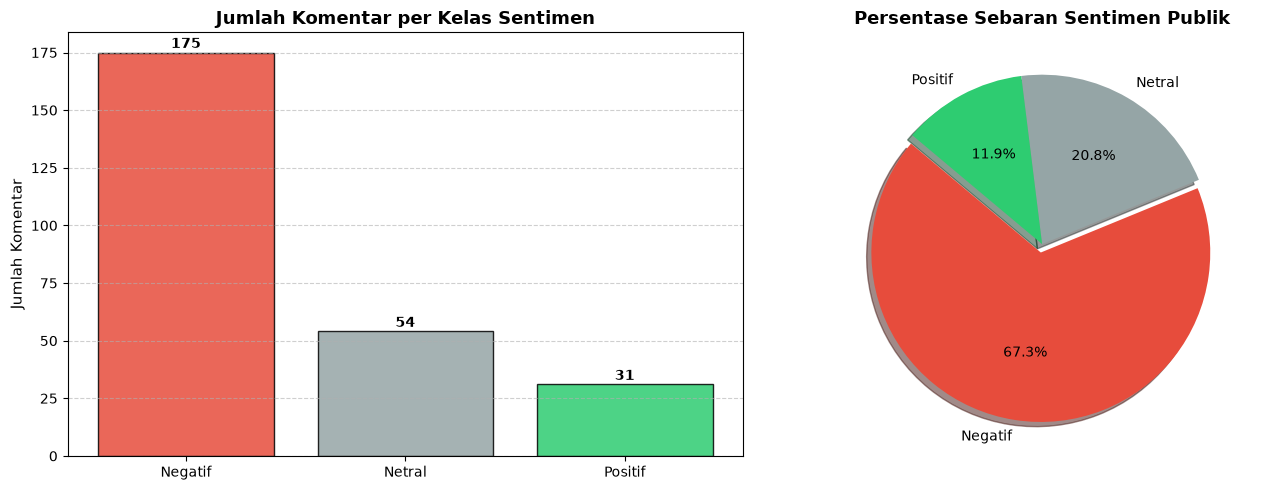

In [10]:
# 10. Visualisasi Distribusi Sentimen (Diagram Batang & Diagram Lingkaran)
palette = {"Positif": "#2ecc71", "Negatif": "#e74c3c", "Netral": "#95a5a6"}
colors = [palette.get(label, "#3498db") for label in sent_counts.index]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Diagram Batang
axes[0].bar(sent_counts.index, sent_counts.values, color=colors, edgecolor="black", alpha=0.85)
axes[0].set_title("Jumlah Komentar per Kelas Sentimen", fontsize=13, fontweight="bold")
axes[0].set_ylabel("Jumlah Komentar", fontsize=11)
axes[0].grid(axis="y", linestyle="--", alpha=0.6)
for i, v in enumerate(sent_counts.values):
    axes[0].text(i, v + 2, f"{v}", ha="center", fontweight="bold")

# Diagram Lingkaran (Pie Chart)
axes[1].pie(
    sent_counts.values,
    labels=sent_counts.index,
    autopct="%1.1f%%",
    startangle=140,
    colors=colors,
    explode=[0.05 if i == 0 else 0 for i in range(len(sent_counts))],
    shadow=True
)
axes[1].set_title("Persentase Sebaran Sentimen Publik", fontsize=13, fontweight="bold")

plt.tight_layout()
plt.show()

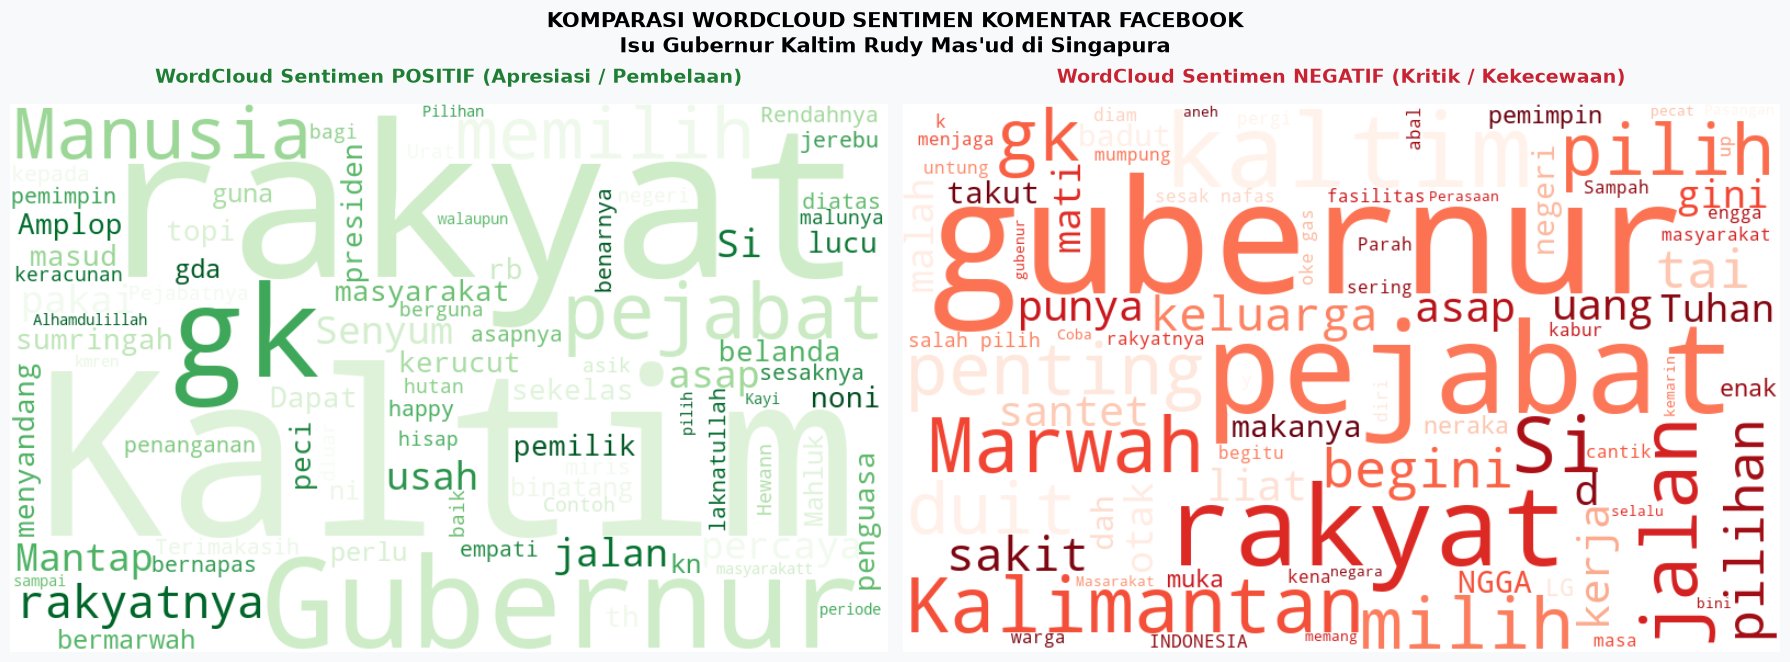

[SUKSES] Seluruh tahapan pipeline berhasil dijalankan sempurna tanpa hambatan!


In [11]:
# 11. Visualisasi WordCloud: Komparasi Kata Kunci Sentimen Positif vs Negatif
INDONESIAN_STOPWORDS = set([
    "yang", "yg", "dan", "di", "ke", "dari", "ini", "itu", "untuk", "utk", "pada", "dgn", "dengan",
    "adalah", "yaitu", "ada", "tidak", "gak", "ga", "nggak", "tak", "bukan", "karena", "karna",
    "juga", "jg", "hanya", "cuma", "bisa", "akan", "sudah", "udah", "telah", "masih", "lagi", "lgi",
    "saya", "aku", "kami", "kita", "dia", "mereka", "kamu", "anda", "beliau", "beliu",
    "saja", "aja", "kan", "lah", "kah", "pun", "ya", "yah", "sih", "kok", "ko", "nih", "tuh", "dong",
    "kalo", "kalau", "jika", "biar", "supaya", "seperti", "kaya", "kayak", "sama", "sm",
    "jadi", "jd", "bikin", "buat", "oleh", "atas", "bawah", "dalam", "dlm", "luar",
    "mau", "ingin", "harus", "pasti", "tahu", "tau", "tapi", "tp", "namun", "padahal",
    "apa", "siapa", "kapan", "dimana", "kenapa", "mengapa", "bagaimana", "gimana",
    "banget", "bgt", "sekali", "sangat", "amat", "terlalu", "paling", "lebih", "lbih",
    "orang", "org", "para", "hal", "banyak", "bnyk", "semua", "semuanya", "gitu", "gtu",
    "klu", "klo", "dr", "tp", "trs", "trus", "sdh", "udh", "klau", "blm", "belum",
    "nya", "bos", "boss", "mah", "deh", "loh", "eh", "ah", "oh", "pas"
])

neg_text = " ".join(df_final[df_final["sentiment_label"] == "Negatif"]["cleaned_comment"].astype(str))
pos_text = " ".join(df_final[df_final["sentiment_label"] == "Positif"]["cleaned_comment"].astype(str))

wc_neg = WordCloud(
    width=800, height=500, background_color="white", colormap="Reds",
    stopwords=INDONESIAN_STOPWORDS, max_words=80
).generate(neg_text)

wc_pos = WordCloud(
    width=800, height=500, background_color="white", colormap="Greens",
    stopwords=INDONESIAN_STOPWORDS, max_words=80
).generate(pos_text)

fig, axes = plt.subplots(1, 2, figsize=(18, 7), facecolor="#f8f9fa")

axes[0].imshow(wc_pos, interpolation="bilinear")
axes[0].set_title("WordCloud Sentimen POSITIF (Apresiasi / Pembelaan)", fontsize=14, fontweight="bold", color="#1e7e34", pad=15)
axes[0].axis("off")

axes[1].imshow(wc_neg, interpolation="bilinear")
axes[1].set_title("WordCloud Sentimen NEGATIF (Kritik / Kekecewaan)", fontsize=14, fontweight="bold", color="#c82333", pad=15)
axes[1].axis("off")

plt.suptitle("KOMPARASI WORDCLOUD SENTIMEN KOMENTAR FACEBOOK\nIsu Gubernur Kaltim Rudy Mas'ud di Singapura", fontsize=15, fontweight="bold", y=0.98)
plt.tight_layout()
plt.savefig("wordcloud_sentiment_comparison.png", dpi=300, bbox_inches="tight")
plt.show()
print("[SUKSES] Seluruh tahapan pipeline berhasil dijalankan sempurna tanpa hambatan!")